# AI-Assisted Data Analytics — Final Project
## Online Retail II: from raw transactions to actionable insights

**Dataset:** UCI *Online Retail II* (Daqing Chen, CC BY 4.0, DOI 10.24432/C5CG6D). All transactions of a UK-based, non-store online retailer between 01/12/2009 and 09/12/2011. The retailer mainly sells all-occasion gift-ware and many customers are wholesalers. Prices are in pounds sterling (£).

**Workflow**

1. Load and merge the two Excel sheets
2. Data cleaning and preparation (duplicates, missing values, cancellations, invalid rows, outliers)
3. Feature engineering (line level and invoice level)
4. Exploratory data analysis and visualization
5. Predictive modeling (Logistic Regression, Decision Tree, Random Forest, SVM, Linear Regression)
6. AI-generated insights and recommendations
7. Exports for the Power BI / Tableau dashboard

**How to run:** put `online_retail_II.xlsx` next to this notebook (or change `DATA_PATH` below) and use *Run All*. The first run reads the Excel file (several minutes for ~1M rows) and caches a combined CSV, so later runs start in seconds.

## 1. Setup

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             ConfusionMatrixDisplay, classification_report,
                             r2_score, mean_absolute_error, mean_squared_error)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)

# ---------------- configuration ----------------
DATA_PATH = r"online_retail_II.xlsx"        # the Excel file with the two sheets
RANDOM_STATE = 42
REVERSAL_MIN_QTY = 10_000           # huge orders that were fully cancelled later are treated as errors
CAP_QUANTILE = 0.99                 # winsorizing level for Quantity
SVM_MAX_TRAIN = 15_000              # SVM is slow on big data, so it trains on a stratified subsample
NON_PRODUCT = ["POST", "D", "M", "BANK CHARGES", "ADJUST", "ADJUST2", "TEST001", "TEST002",
               "PADS", "DOT", "CRUK", "S", "AMAZONFEE"]

OUT = Path("outputs")
FIG = OUT / "figures"
PBI = OUT / "powerbi"
for p in (OUT, FIG, PBI):
    p.mkdir(parents=True, exist_ok=True)

cleaning_log = []
def log_step(step, rows, removed=None, note=""):
    cleaning_log.append({"step": step, "rows_after": rows, "rows_removed": removed, "note": note})

def save_show(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 2. Load and merge the two sheets

The two sheets (2009-2010 and 2010-2011) have identical columns and are one continuous business, so they are **concatenated into a single table**. A `source_sheet` column remembers where every row came from, so nothing is lost and either period can still be isolated with a filter or slicer. Analyzing the sheets separately would break the time series, so the combined table is used for everything from here on.

In [2]:
CACHE = Path("online_retail_combined.csv")      # delete this file to force a fresh read from Excel

if CACHE.exists():
    df = pd.read_csv(CACHE, parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})
    print(f"Loaded cached file: {CACHE}")
else:
    sheets = pd.read_excel(DATA_PATH, sheet_name=None)      # reads EVERY sheet (slow for ~1M rows)
    print({name: sheet.shape for name, sheet in sheets.items()})

    frames = []
    for name, sheet in sheets.items():
        sheet = sheet.copy()
        sheet["source_sheet"] = name.replace("Year", "").strip()      # e.g. "2009-2010"
        frames.append(sheet)

    # validation 1: identical columns in every sheet
    base_cols = set(frames[0].columns) - {"source_sheet"}
    assert all(set(f.columns) - {"source_sheet"} == base_cols for f in frames), "Sheets have different columns"

    df = pd.concat(frames, ignore_index=True)

    # validation 2: row counts add up
    assert len(df) == sum(len(f) for f in frames), "Row count mismatch after concat"
    df.to_csv(CACHE, index=False)
    print(f"Combined sheets and cached to {CACHE}")

# validation 3: consistent types (mixed invoice/stock codes are read as text)
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Shape:", df.shape)
display(df.dtypes.to_frame("dtype").T)
print("Date range per source sheet (they overlap in December 2010):")
display(df.groupby("source_sheet")["InvoiceDate"].agg(["min", "max", "count"]))
display(df.head())
log_step("0. Raw rows (both sheets combined)", len(df))

{'Year 2009-2010': (525461, 8), 'Year 2010-2011': (541910, 8)}
Combined sheets and cached to online_retail_combined.csv
Shape: (1067371, 9)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet
dtype,object,object,object,int64,datetime64[ns],float64,float64,object,object


Date range per source sheet (they overlap in December 2010):


,min,max,count
source_sheet,,,
2009-2010,2009-12-01 07:45:00,2010-12-09 20:01:00,525461
2010-2011,2010-12-01 08:26:00,2011-12-09 12:50:00,541910


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom,2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom,2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom,2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom,2009-2010


## 3. Data cleaning and preparation

### 3.1 Duplicates

The sheets overlap in December 2010, so some transactions appear in both. Some rows are also repeated inside a single sheet. The two kinds are separated before anything is dropped.

In [3]:
key_cols = [c for c in df.columns if c != "source_sheet"]

dup_all = df.duplicated(subset=key_cols, keep=False)          # every copy, including the first
dup_removable = df.duplicated(subset=key_cols, keep="first")  # only the extra copies
print(f"Rows involved in a duplicate (all copies): {dup_all.sum():,}")
print(f"Removable duplicate rows:                  {dup_removable.sum():,} ({dup_removable.mean():.2%})")

sheets_per_group = df[dup_all].groupby(key_cols, dropna=False)["source_sheet"].nunique()
print(f"Duplicate groups spanning both sheets (the Dec-2010 overlap): {(sheets_per_group == 2).sum():,}")
print(f"Duplicate groups inside a single sheet (repeated rows):       {(sheets_per_group == 1).sum():,}")

before = len(df)
df = df.drop_duplicates(subset=key_cols, keep="first").reset_index(drop=True)
print(f"Rows before: {before:,} | after: {len(df):,} | removed: {before - len(df):,}")
log_step("1. Remove exact duplicates", len(df), before - len(df), "sheet overlap + repeated rows")

Rows involved in a duplicate (all copies): 67,242
Removable duplicate rows:                  34,335 (3.22%)
Duplicate groups spanning both sheets (the Dec-2010 overlap): 22,202
Duplicate groups inside a single sheet (repeated rows):       10,705
Rows before: 1,067,371 | after: 1,033,036 | removed: 34,335


### 3.2 Missing values

Two columns have gaps. Missing descriptions are diagnosed first, and missing customer IDs are kept and flagged rather than dropped, because nearly a quarter of all rows would be lost otherwise.

In [4]:
missing = df.isna().sum().to_frame("missing")
missing["pct"] = missing["missing"] / len(df) * 100
display(missing)

no_desc = df[df["Description"].isna()]
print(f"Rows without Description: {len(no_desc):,} | share with Price == 0: {(no_desc['Price'] == 0).mean():.1%}")
display(no_desc[["Quantity", "Price"]].describe())
print("Missing descriptions are stock adjustments (price 0), not sales, so they are removed in step 3.3.")

# Guest checkouts: keep the rows, flag them, and make Customer ID a clean string
df["IsGuest"] = df["Customer ID"].isna()
df["Customer ID"] = df["Customer ID"].map(lambda v: "Guest" if pd.isna(v) else str(int(v)))
print(df["IsGuest"].value_counts())

,missing,pct
Invoice,0,0.00
StockCode,0,0.00
Description,4275,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,235151,22.76
Country,0,0.00
source_sheet,0,0.00


Rows without Description: 4,275 | share with Price == 0: 100.0%


,Quantity,Price
count,"4,275.00","4,275.00"
mean,-17.37,0.00
std,515.94,0.00
min,"-9,600.00",0.00
25%,-28.00,0.00
50%,-4.00,0.00
75%,3.00,0.00
max,"9,600.00",0.00


Missing descriptions are stock adjustments (price 0), not sales, so they are removed in step 3.3.
IsGuest
False    797885
True     235151
Name: count, dtype: int64


### 3.3 Cancellations and invalid rows

* Invoices starting with **C** are cancellations. They are kept in a **separate table** (`df_cancel`) because the cancellation rate is a useful KPI, and excluded from the sales table.
* In the sales table, rows with `Quantity <= 0` or `Price <= 0` are adjustments, not sales.
* Non-product stock codes (postage, fees, manual entries) distort product analysis.
* Invoice numbers that are not exactly 6 digits (for example `A563185 "Adjust bad debt"`) are accounting entries, not sales.

In [5]:
df["IsCancelled"] = df["Invoice"].str.startswith("C")
print(df["IsCancelled"].value_counts())

n_start = len(df)
df_cancel = df[df["IsCancelled"] & ~df["StockCode"].isin(NON_PRODUCT)].copy()     # product cancellations only
df_sales = df[~df["IsCancelled"]].copy()
log_step("2a. Non-cancelled lines", len(df_sales), n_start - len(df_sales), "cancellations moved to df_cancel")

df_valid = df_sales[(df_sales["Quantity"] > 0) & (df_sales["Price"] > 0)].copy()
log_step("2b. Quantity > 0 and Price > 0", len(df_valid), len(df_sales) - len(df_valid), "adjustments / write-offs")

df_clean = df_valid[~df_valid["StockCode"].isin(NON_PRODUCT)].copy()
log_step("2c. Remove non-product stock codes", len(df_clean), len(df_valid) - len(df_clean), "postage, fees, manual")

bad_inv = df_clean[~df_clean["Invoice"].str.match(r"^\d{6}$")]
print("Invoices that are not exactly 6 digits:")
display(bad_inv[["Invoice", "StockCode", "Description", "Quantity", "Price"]].head(10))
n0 = len(df_clean)
df_clean = df_clean[df_clean["Invoice"].str.match(r"^\d{6}$")].copy()
log_step("2d. Remove non-sale invoice numbers", len(df_clean), n0 - len(df_clean), "e.g. A563185 bad debt")

print(f"Cancellation lines kept in df_cancel (product only): {len(df_cancel):,}")
print("Sanity: missing Description left =", df_clean["Description"].isna().sum(),
      "| min Quantity =", df_clean["Quantity"].min(), "| min Price =", df_clean["Price"].min())

IsCancelled
False    1013932
True       19104
Name: count, dtype: int64
Invoices that are not exactly 6 digits:


,Invoice,StockCode,Description,Quantity,Price
794039,A563185,B,Adjust bad debt,1,"11,062.06"


Cancellation lines kept in df_cancel (product only): 17,922
Sanity: missing Description left = 0 | min Quantity = 1 | min Price = 0.03


### 3.4 Orders that were fully reversed

A huge order that was cancelled in full later (same customer, same product, same quantity) is a data-entry mistake, not real demand. The check below is data-driven: it only removes lines of at least `REVERSAL_MIN_QTY` units that have an exactly matching cancellation (the matching cancellation lines are removed too, so they do not inflate the cancellation KPI). Large orders that were *not* cancelled are real wholesale demand and are kept.

In [6]:
cancel_keys = (df_cancel[df_cancel["Customer ID"] != "Guest"]
               .assign(Quantity=lambda d: -d["Quantity"])[["Customer ID", "StockCode", "Quantity"]]
               .drop_duplicates())

big = df_clean[df_clean["Quantity"] >= REVERSAL_MIN_QTY].rename_axis("row_id").reset_index()
reversed_lines = big.merge(cancel_keys, on=["Customer ID", "StockCode", "Quantity"], how="inner")
print("Large orders with an exactly matching cancellation (removed):")
display(reversed_lines[["Invoice", "StockCode", "Description", "Quantity", "Price", "InvoiceDate"]])

kept_big = big[~big["row_id"].isin(reversed_lines["row_id"])]
print(f"Large orders (>= {REVERSAL_MIN_QTY:,} units) kept as legitimate wholesale demand: {len(kept_big)}")

n0 = len(df_clean)
df_clean = df_clean.drop(index=reversed_lines["row_id"].unique()).copy()
log_step("2e. Remove fully reversed giant orders", len(df_clean), n0 - len(df_clean), "order + matching cancellation")

# the matching cancellations are removed too, so they do not inflate the cancellation KPI
rev_keys = (reversed_lines[["Customer ID", "StockCode", "Quantity"]].drop_duplicates()
            .assign(Quantity=lambda d: -d["Quantity"], _rev=1))
is_reversal = df_cancel.merge(rev_keys, on=["Customer ID", "StockCode", "Quantity"], how="left")["_rev"].notna().to_numpy()
df_cancel = df_cancel[~is_reversal].copy()
print(f"Matching cancellation lines removed from df_cancel: {is_reversal.sum()} | df_cancel now has {len(df_cancel):,} lines")

df_clean["TotalPrice"] = df_clean["Quantity"] * df_clean["Price"]

Large orders with an exactly matching cancellation (removed):


,Invoice,StockCode,Description,Quantity,Price,InvoiceDate
0,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00
1,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00


Large orders (>= 10,000 units) kept as legitimate wholesale demand: 9
Matching cancellation lines removed from df_cancel: 2 | df_cancel now has 17,920 lines


### 3.5 Outliers

This is wholesale data, so large values are often legitimate. The approach is *flag, inspect, then cap*:

1. **IQR rule (1.5 × IQR)** flags unusually large values. The lower bounds are negative, so only the upper bound matters.
2. **Isolation Forest** is an unsupervised anomaly detector used as a second opinion. It looks at quantity and price together.
3. Instead of deleting, `Quantity` is **winsorized at the 99th percentile** (`Quantity_capped`). Original columns stay untouched. Original values feed revenue KPIs, capped values feed modeling and distribution charts.

,column,lower,upper,outliers,share
0,Quantity,-15.50,28.50,53017,0.05
1,Price,-3.07,8.45,75400,0.08
2,TotalPrice,-16.23,38.06,82404,0.08


Ten largest lines by TotalPrice:


,Invoice,Description,Quantity,Price,TotalPrice
717210,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00"
426971,530715,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,"15,818.40"
225363,511465,PINK PAPER PARASOL,3500,2.55,"8,925.00"
842021,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,"7,144.72"
548563,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40"
655495,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,"6,539.40"
455824,533027,PAPER CHAIN KIT 50'S CHRISTMAS,835,6.95,"5,803.25"
375425,525968,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,1.66,"5,179.20"
914482,573003,RABBIT NIGHT LIGHT,2400,2.08,"4,992.00"
548561,540815,WHITE HANGING HEART T-LIGHT HOLDER,1930,2.55,"4,921.50"


IQR-flagged rows: 82,404 | Isolation-Forest anomalies: 10,001 | flagged by both: 8,541
99% percentile of Quantity (cap): 108 | rows capped: 9,789


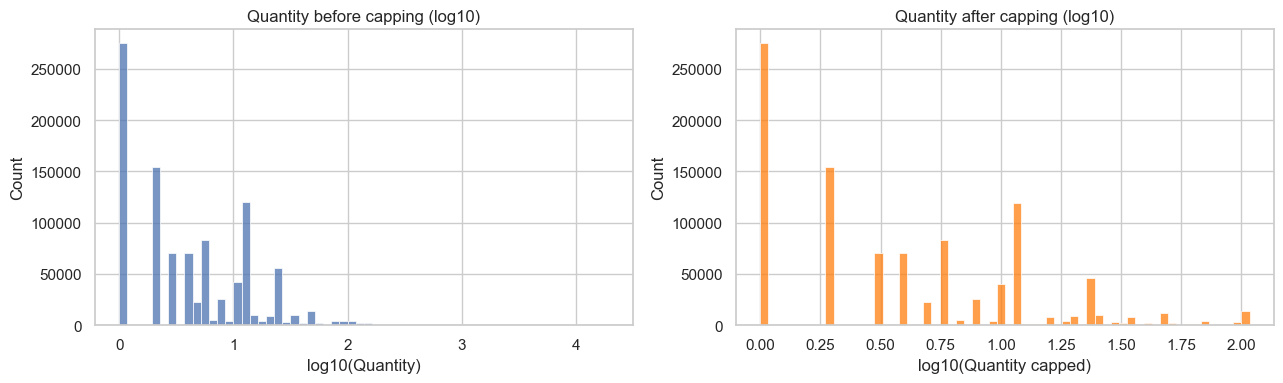

In [7]:
def iqr_bounds(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

rows = []
for col in ["Quantity", "Price", "TotalPrice"]:
    lo, hi = iqr_bounds(df_clean[col])
    n = ((df_clean[col] < lo) | (df_clean[col] > hi)).sum()
    rows.append({"column": col, "lower": lo, "upper": hi, "outliers": n, "share": n / len(df_clean)})
display(pd.DataFrame(rows))

print("Ten largest lines by TotalPrice:")
display(df_clean.nlargest(10, "TotalPrice")[["Invoice", "Description", "Quantity", "Price", "TotalPrice"]])

# Tier 1: flag (keep) rows above the IQR upper bound on TotalPrice
_, hi_total = iqr_bounds(df_clean["TotalPrice"])
df_clean["IsOutlier"] = df_clean["TotalPrice"] > hi_total

# Second opinion: Isolation Forest on log(quantity), log(price)
iso = IsolationForest(n_estimators=100, contamination=0.01, random_state=RANDOM_STATE, n_jobs=-1)
df_clean["IsAnomaly"] = iso.fit_predict(np.log1p(df_clean[["Quantity", "Price"]])) == -1
print(f"IQR-flagged rows: {df_clean['IsOutlier'].sum():,} | Isolation-Forest anomalies: {df_clean['IsAnomaly'].sum():,} "
      f"| flagged by both: {(df_clean['IsOutlier'] & df_clean['IsAnomaly']).sum():,}")

# Tier 2: winsorize Quantity (Price is left alone: high prices are real products)
q_cap = df_clean["Quantity"].quantile(CAP_QUANTILE)
df_clean["Quantity_capped"] = df_clean["Quantity"].clip(upper=q_cap)
df_clean["TotalPrice_capped"] = df_clean["Quantity_capped"] * df_clean["Price"]
print(f"{CAP_QUANTILE:.0%} percentile of Quantity (cap): {q_cap:,.0f} | rows capped: {(df_clean['Quantity'] > q_cap).sum():,}")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(np.log10(df_clean["Quantity"]), bins=60, ax=ax[0])
ax[0].set(title="Quantity before capping (log10)", xlabel="log10(Quantity)")
sns.histplot(np.log10(df_clean["Quantity_capped"]), bins=60, ax=ax[1], color="tab:orange")
ax[1].set(title="Quantity after capping (log10)", xlabel="log10(Quantity capped)")
save_show("01_outlier_capping")
log_step("3. Outliers flagged and capped (no rows removed)", len(df_clean), 0, "IsOutlier, IsAnomaly, *_capped")

Most purchases involve small quantities, while a few transactions have unusually large amounts. After capping, these extreme values are reduced, making the data more balanced without changing the overall distribution significantly. This helps prevent unusually large orders from having too much influence on the analysis while keeping the typical purchasing patterns intact.

### 3.6 Date features and the cleaned dataset

In [8]:
d = df_clean["InvoiceDate"]
df_clean["Year"] = d.dt.year
df_clean["Month"] = d.dt.month
df_clean["YearMonth"] = d.dt.to_period("M").astype(str)
df_clean["DayOfWeek"] = d.dt.day_name()
df_clean["Hour"] = d.dt.hour

# the same date features for the cancellations table (used in the dashboard)
df_cancel["Year"] = df_cancel["InvoiceDate"].dt.year
df_cancel["Month"] = df_cancel["InvoiceDate"].dt.month
df_cancel["YearMonth"] = df_cancel["InvoiceDate"].dt.to_period("M").astype(str)
df_cancel["TotalPrice"] = df_cancel["Quantity"] * df_cancel["Price"]

df_clean = df_clean.reset_index(drop=True)
df_clean.to_csv(OUT / "online_retail_clean_final.csv", index=False)

cleaning_summary = pd.DataFrame(cleaning_log)
cleaning_summary.to_csv(OUT / "cleaning_log.csv", index=False)
print("Cleaning log (use these numbers in the walkthrough video):")
display(cleaning_summary)
print("Final cleaned shape:", df_clean.shape)
print(f"Rows kept: {len(df_clean) / cleaning_summary.loc[0, 'rows_after']:.1%} of the raw rows")

Cleaning log (use these numbers in the walkthrough video):


,step,rows_after,rows_removed,note
0,0. Raw rows (both sheets combined),1067371,NaN,
1,1. Remove exact duplicates,1033036,"34,335.00",sheet overlap + repeated rows
2,2a. Non-cancelled lines,1013932,"19,104.00",cancellations moved to df_cancel
3,2b. Quantity > 0 and Price > 0,1007913,"6,019.00",adjustments / write-offs
4,2c. Remove non-product stock codes,1003690,"4,223.00","postage, fees, manual"
5,2d. Remove non-sale invoice numbers,1003689,1.00,e.g. A563185 bad debt
6,2e. Remove fully reversed giant orders,1003687,2.00,order + matching cancellation
7,3. Outliers flagged and capped (no rows removed),1003687,0.00,"IsOutlier, IsAnomaly, *_capped"


Final cleaned shape: (1003687, 21)
Rows kept: 94.0% of the raw rows


## 4. Feature engineering: the invoice-level table

The raw data is at line-item level. For modeling, one row per **invoice** is more natural (one purchase = one decision), so lines are aggregated into an invoice table. The line-level table stays for EDA and the dashboard.

In [9]:
df_inv = (df_clean.groupby("Invoice")
          .agg(InvoiceDate=("InvoiceDate", "min"),
               Customer_ID=("Customer ID", "first"),
               Country=("Country", "first"),
               source_sheet=("source_sheet", "first"),
               n_lines=("StockCode", "size"),
               n_items=("StockCode", "nunique"),
               total_qty=("Quantity", "sum"),
               total_qty_capped=("Quantity_capped", "sum"),
               invoice_total=("TotalPrice", "sum"))
          .reset_index())

df_inv["avg_unit_price"] = df_inv["invoice_total"] / df_inv["total_qty"]
df_inv["IsGuest"] = (df_inv["Customer_ID"] == "Guest").astype(int)
df_inv["Year"] = df_inv["InvoiceDate"].dt.year
df_inv["Month"] = df_inv["InvoiceDate"].dt.month
df_inv["DayOfWeek"] = df_inv["InvoiceDate"].dt.day_name()
df_inv["Hour"] = df_inv["InvoiceDate"].dt.hour

top_countries = df_inv["Country"].value_counts().nlargest(8).index
df_inv["Country_grp"] = np.where(df_inv["Country"].isin(top_countries), df_inv["Country"], "Other")
df_inv["log_total_qty"] = np.log1p(df_inv["total_qty_capped"])
df_inv["log_invoice_total"] = np.log1p(df_inv["invoice_total"])

print("Invoice table:", df_inv.shape)
display(df_inv.head())

Invoice table: (39521, 19)


,Invoice,InvoiceDate,Customer_ID,Country,source_sheet,n_lines,n_items,total_qty,total_qty_capped,invoice_total,avg_unit_price,IsGuest,Year,Month,DayOfWeek,Hour,Country_grp,log_total_qty,log_invoice_total
0,489434,2009-12-01 07:45:00,13085,United Kingdom,2009-2010,8,8,166,166,505.30,3.04,0,2009,12,Tuesday,7,United Kingdom,5.12,6.23
1,489435,2009-12-01 07:46:00,13085,United Kingdom,2009-2010,4,4,60,60,145.80,2.43,0,2009,12,Tuesday,7,United Kingdom,4.11,4.99
2,489436,2009-12-01 09:06:00,13078,United Kingdom,2009-2010,19,19,193,193,630.33,3.27,0,2009,12,Tuesday,9,United Kingdom,5.27,6.45
3,489437,2009-12-01 09:08:00,15362,United Kingdom,2009-2010,23,23,145,145,310.75,2.14,0,2009,12,Tuesday,9,United Kingdom,4.98,5.74
4,489438,2009-12-01 09:24:00,18102,United Kingdom,2009-2010,17,17,826,826,"2,286.24",2.77,0,2009,12,Tuesday,9,United Kingdom,6.72,7.74


## 5. Exploratory data analysis

### 5.1 Revenue trend over time

,YearMonth,Revenue,Orders,Units,AOV
19,2011-07,"688,802.67",1452,399302,474.38
20,2011-08,"724,708.16",1340,420709,540.83
21,2011-09,"1,029,245.38",1819,568719,565.83
22,2011-10,"1,104,030.92",2005,619612,550.64
23,2011-11,"1,453,265.98",2751,746975,528.27
24,2011-12,"446,229.65",815,231657,547.52


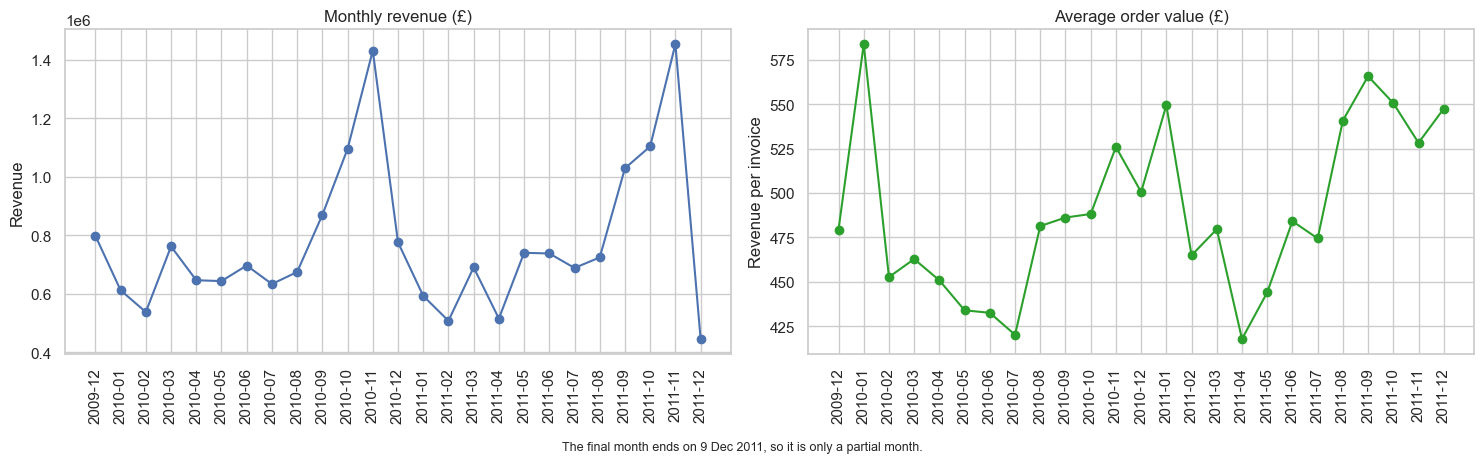

In [10]:
monthly = (df_clean.groupby("YearMonth")
           .agg(Revenue=("TotalPrice", "sum"), Orders=("Invoice", "nunique"), Units=("Quantity", "sum"))
           .reset_index())
monthly["AOV"] = monthly["Revenue"] / monthly["Orders"]
display(monthly.tail(6))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].plot(monthly["YearMonth"], monthly["Revenue"], marker="o")
ax[0].set(title="Monthly revenue (£)", xlabel="", ylabel="Revenue")
ax[1].plot(monthly["YearMonth"], monthly["AOV"], marker="o", color="tab:green")
ax[1].set(title="Average order value (£)", xlabel="", ylabel="Revenue per invoice")
for a in ax:
    a.tick_params(axis="x", rotation=90)
fig.text(0.5, -0.02, "The final month ends on 9 Dec 2011, so it is only a partial month.", ha="center", fontsize=9)
save_show("02_monthly_revenue_aov")

Monthly revenue fluctuates throughout the period, with noticeable peaks in November 2010 and November 2011. This suggests a possible seasonal increase in sales toward the end of the year. Average order value also varies, but generally improves during the later months of 2011, suggesting customers may be spending more per order. The sharp revenue drop in December 2011 shouldn't be treated as a decline, since the data only covers the first 9 days of that month.

### 5.2 Countries and products

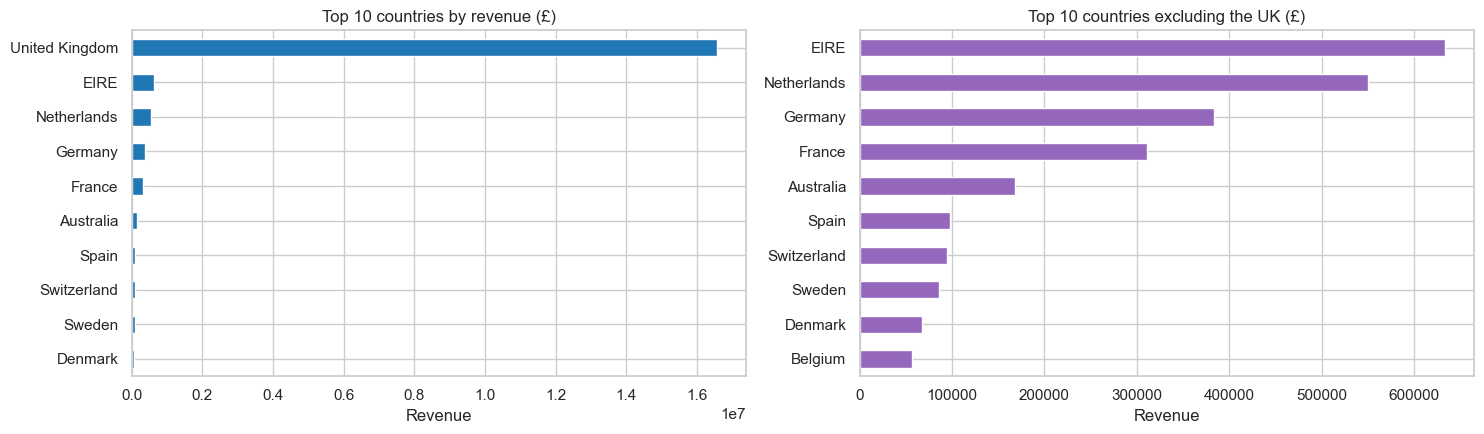

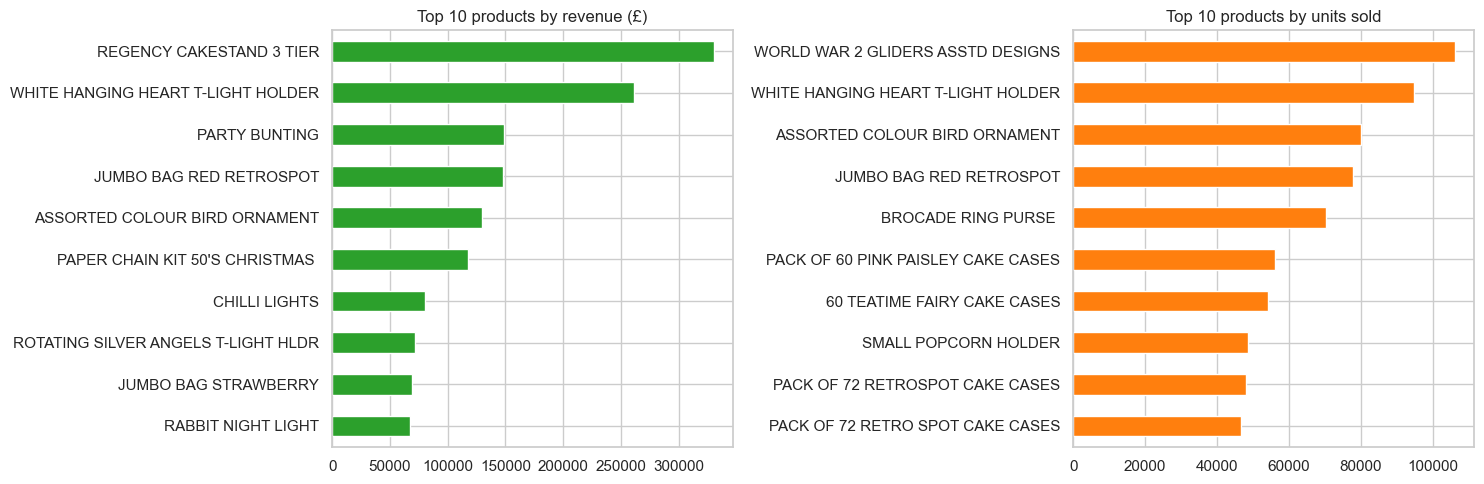

In [11]:
by_country = df_clean.groupby("Country")["TotalPrice"].sum().sort_values(ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
by_country.head(10).sort_values().plot.barh(ax=ax[0], color="tab:blue")
ax[0].set(title="Top 10 countries by revenue (£)", xlabel="Revenue", ylabel="")
by_country.drop("United Kingdom", errors="ignore").head(10).sort_values().plot.barh(ax=ax[1], color="tab:purple")
ax[1].set(title="Top 10 countries excluding the UK (£)", xlabel="Revenue", ylabel="")
save_show("03_country_revenue")

by_prod = df_clean.groupby("Description").agg(Revenue=("TotalPrice", "sum"), Units=("Quantity", "sum"))
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
by_prod["Revenue"].nlargest(10).sort_values().plot.barh(ax=ax[0], color="tab:green")
ax[0].set(title="Top 10 products by revenue (£)", ylabel="")
by_prod["Units"].nlargest(10).sort_values().plot.barh(ax=ax[1], color="tab:orange")
ax[1].set(title="Top 10 products by units sold", ylabel="")
save_show("04_top_products")

The UK generates by far the most revenue, showing that the business relies heavily on its domestic market. Outside the UK, Ireland and the Netherlands are the strongest markets, followed by Germany and France.

Looking at products, Regency Cakestand 3 Tier brings in the highest revenue, while World War 2 Gliders sells the most units. This shows that the best-selling products by quantity aren't necessarily the ones generating the most revenue. Some products may sell fewer units but contribute more revenue because of their higher prices.

### 5.3 Distributions

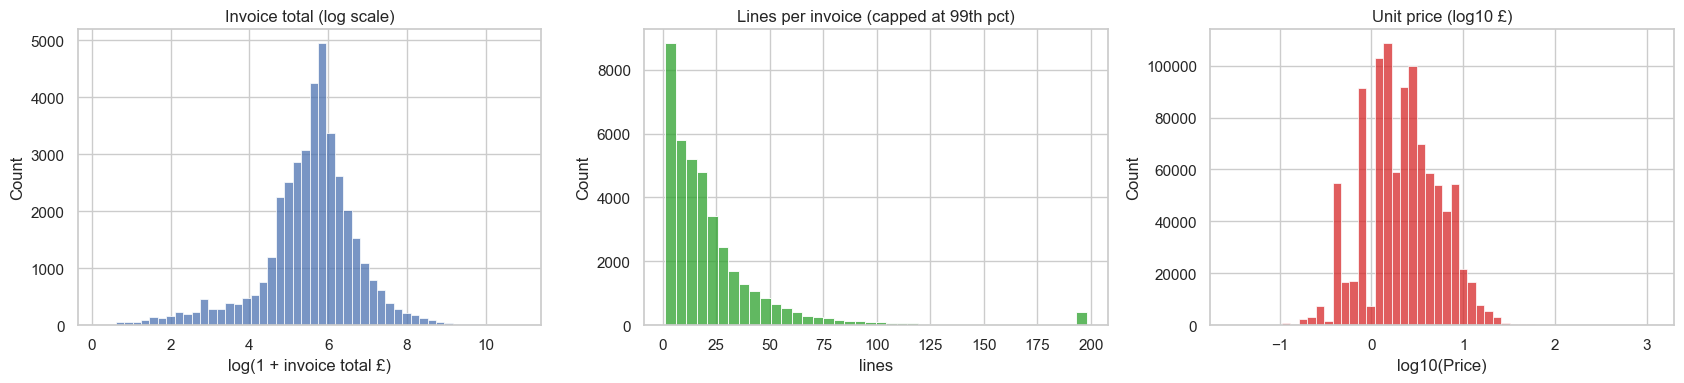

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(df_inv["log_invoice_total"], bins=50, ax=ax[0])
ax[0].set(title="Invoice total (log scale)", xlabel="log(1 + invoice total £)")
sns.histplot(df_inv["n_lines"].clip(upper=df_inv["n_lines"].quantile(0.99)), bins=40, ax=ax[1], color="tab:green")
ax[1].set(title="Lines per invoice (capped at 99th pct)", xlabel="lines")
sns.histplot(np.log10(df_clean["Price"]), bins=50, ax=ax[2], color="tab:red")
ax[2].set(title="Unit price (log10 £)", xlabel="log10(Price)")
save_show("05_distributions")

Most invoices fall within a similar total value range, while a few are significantly higher or lower. Most invoices also contain a relatively small number of items, with only a few having unusually large numbers of lines. Unit prices are mostly concentrated in the lower-to-middle range, suggesting that the business mainly sells affordable products, with some higher-priced items.

### 5.4 Relationships between variables

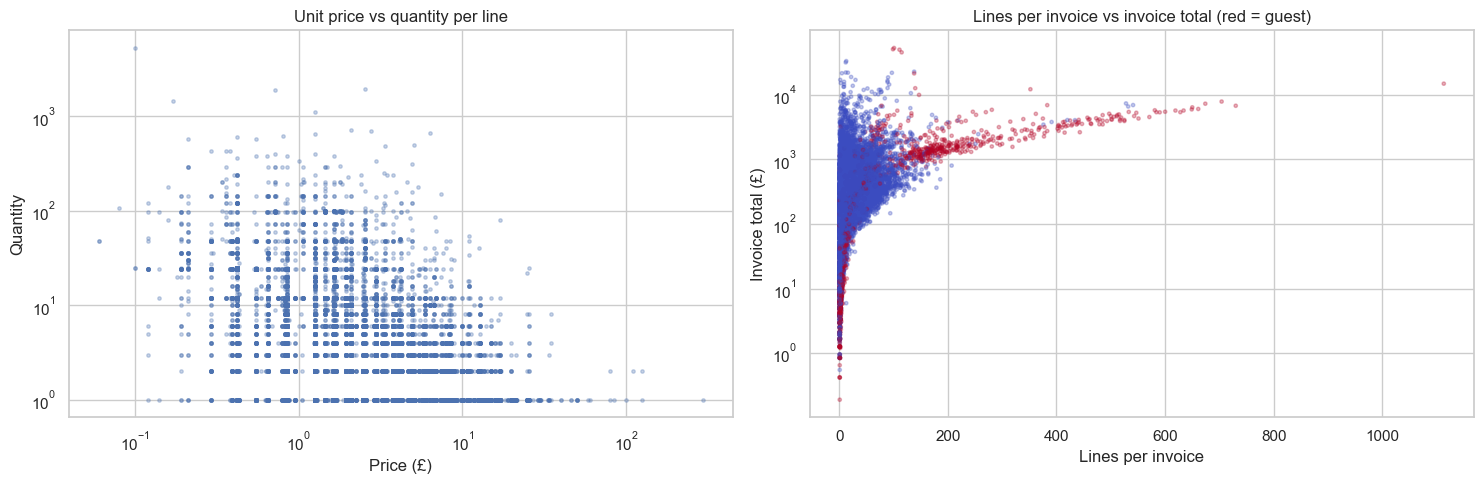

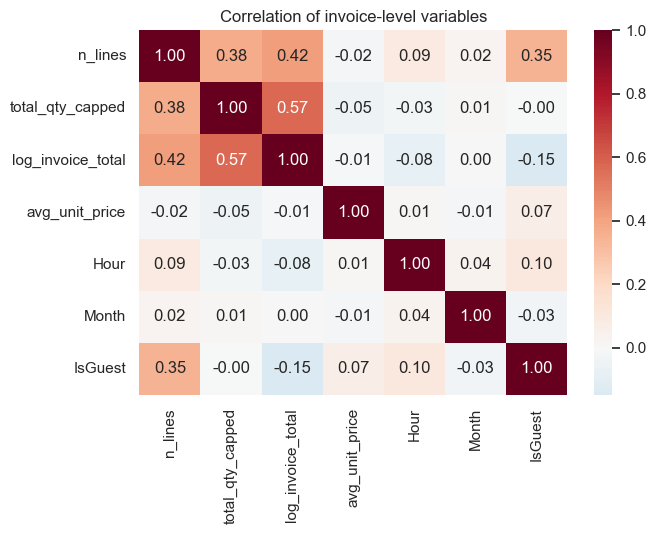

In [13]:
sample_lines = df_clean.sample(min(20_000, len(df_clean)), random_state=RANDOM_STATE)
sample_inv = df_inv.sample(min(20_000, len(df_inv)), random_state=RANDOM_STATE)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].scatter(sample_lines["Price"], sample_lines["Quantity"], s=6, alpha=0.3)
ax[0].set(xscale="log", yscale="log", title="Unit price vs quantity per line", xlabel="Price (£)", ylabel="Quantity")
sc = ax[1].scatter(sample_inv["n_lines"], sample_inv["invoice_total"], s=6, alpha=0.3,
                   c=sample_inv["IsGuest"], cmap="coolwarm")
ax[1].set(yscale="log", title="Lines per invoice vs invoice total (red = guest)", xlabel="Lines per invoice", ylabel="Invoice total (£)")
save_show("06_scatter_relationships")

corr_cols = ["n_lines", "total_qty_capped", "log_invoice_total", "avg_unit_price", "Hour", "Month", "IsGuest"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df_inv[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation of invoice-level variables")
save_show("07_correlation_heatmap")

The analysis shows that **invoice value is more closely related to the quantity purchased (0.57) than the number of product lines (0.42)**. This suggests that customers buying larger quantities tend to generate more revenue.

Most purchases involve low-priced items in small quantities, while expensive products are generally bought in fewer units.

Interestingly, guest customers tend to have more product lines per invoice (0.35), but their invoice totals show a weak negative correlation (-0.15). This suggests that having more items in a basket doesn't always mean spending more.

Overall, **purchase quantity appears to be a stronger driver of revenue than product variety**, while time and month show little linear relationship with individual invoice values.

### 5.5 When do customers buy?

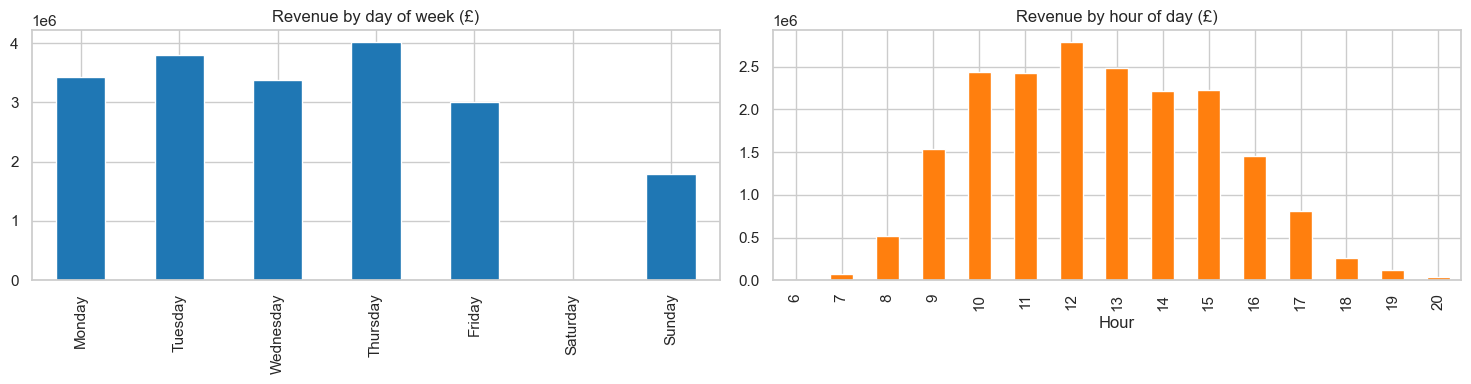

Revenue by calendar year and original sheet (a row can appear under one sheet only after de-duplication):


source_sheet,2009-2010,2010-2011
Year,,
2009,"798,618.53",0.00
2010,"9,013,736.56","368,062.57"
2011,0.00,"9,232,987.98"


In [14]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_dow = df_clean.groupby("DayOfWeek")["TotalPrice"].sum().reindex(order).dropna()
by_hour = df_clean.groupby("Hour")["TotalPrice"].sum()

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
by_dow.plot.bar(ax=ax[0], color="tab:blue")
ax[0].set(title="Revenue by day of week (£)", xlabel="")
by_hour.plot.bar(ax=ax[1], color="tab:orange")
ax[1].set(title="Revenue by hour of day (£)", xlabel="Hour")
save_show("08_timing")

by_year_sheet = df_clean.groupby(["Year", "source_sheet"])["TotalPrice"].sum().unstack(fill_value=0)
print("Revenue by calendar year and original sheet (a row can appear under one sheet only after de-duplication):")
display(by_year_sheet)

Revenue is strongest during weekdays, particularly on Thursday and Tuesday, while Sunday generates noticeably less revenue. Saturday shows no recorded sales, which may indicate that the business is closed or does not process transactions that day.

Looking at hourly sales, revenue peaks around **12 PM**, with the busiest period falling between **10 AM and 3 PM**. Sales drop significantly toward the evening.

Overall, these patterns suggest that the business should focus its staffing, inventory, and daily operations around peak weekday and midday demand.

## 6. Predictive modeling

**Target definition.** `HighValue = 1` if the invoice total is above the median invoice total, otherwise 0. The median split gives balanced classes (about 50/50), so accuracy and the confusion matrix are meaningful. The same invoice table is also used for **Linear Regression**, which predicts the (log) invoice total directly.

**Avoiding leakage.** The target is built from `quantity × price`. Features therefore include order *size and context* (number of lines, total quantity, guest flag, country, month, weekday, hour) and deliberately **exclude price information** (`avg_unit_price`, `invoice_total`), because quantity and price together would reproduce the target exactly.

**Evaluation.** 80/20 stratified train/test split. Accuracy and the confusion matrix are the required metrics. Precision, recall, F1, ROC-AUC and 5-fold cross-validation are added as a robustness check.

In [15]:
HV_THRESHOLD = df_inv["invoice_total"].median()
df_inv["HighValue"] = (df_inv["invoice_total"] > HV_THRESHOLD).astype(int)
print(f"High-value threshold (median invoice total): £{HV_THRESHOLD:,.2f}")
print(df_inv["HighValue"].value_counts(normalize=True).rename("share"))

num_feats = ["n_lines", "log_total_qty", "Hour"]
bin_feats = ["IsGuest"]
cat_feats = ["Country_grp", "DayOfWeek", "Month"]
features = num_feats + bin_feats + cat_feats

def make_prep():
    return ColumnTransformer([
        ("num", StandardScaler(), num_feats),
        ("bin", "passthrough", bin_feats),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_feats),
    ])

X = df_inv[features].copy()
y = df_inv["HighValue"]
y_reg = df_inv["log_invoice_total"]

X_train, X_test, y_train, y_test, yreg_train, yreg_test = train_test_split(
    X, y, y_reg, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Train: {len(X_train):,} invoices | Test: {len(X_test):,} invoices")

High-value threshold (median invoice total): £301.34
HighValue
0   0.50
1   0.50
Name: share, dtype: float64
Train: 31,616 invoices | Test: 7,905 invoices


In [16]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=5,
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "SVM (RBF)": SVC(kernel="rbf", C=1.0, gamma="scale"),
}

pipes, preds, results = {}, {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", make_prep()), ("model", model)])

    if name.startswith("SVM") and len(X_train) > SVM_MAX_TRAIN:
        Xt, _, yt, _ = train_test_split(X_train, y_train, train_size=SVM_MAX_TRAIN,
                                        stratify=y_train, random_state=RANDOM_STATE)
    else:
        Xt, yt = X_train, y_train
    pipe.fit(Xt, yt)

    pred = pipe.predict(X_test)
    score = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X_test)
    cv = (cross_val_score(Pipeline([("prep", make_prep()), ("model", model)]), X_train, y_train,
                          cv=5, scoring="accuracy", n_jobs=-1).mean()
          if not name.startswith("SVM") else np.nan)

    pipes[name], preds[name] = pipe, pred
    results.append({"model": name,
                    "train_accuracy": accuracy_score(yt, pipe.predict(Xt)),
                    "test_accuracy": accuracy_score(y_test, pred),
                    "cv_accuracy_5fold": cv,
                    "precision": precision_score(y_test, pred),
                    "recall": recall_score(y_test, pred),
                    "f1": f1_score(y_test, pred),
                    "roc_auc": roc_auc_score(y_test, score)})

results_df = pd.DataFrame(results).sort_values("test_accuracy", ascending=False).reset_index(drop=True)
results_df.to_csv(OUT / "model_results.csv", index=False)
display(results_df)
best_name = results_df.loc[0, "model"]
print("Best model by test accuracy:", best_name)

,model,train_accuracy,test_accuracy,cv_accuracy_5fold,precision,recall,f1,roc_auc
0,Decision Tree,0.85,0.84,0.84,0.83,0.85,0.84,0.92
1,Random Forest,0.85,0.84,0.84,0.83,0.85,0.84,0.92
2,SVM (RBF),0.85,0.83,NaN,0.83,0.84,0.83,0.91
3,Logistic Regression,0.84,0.83,0.84,0.82,0.85,0.83,0.92


Best model by test accuracy: Decision Tree


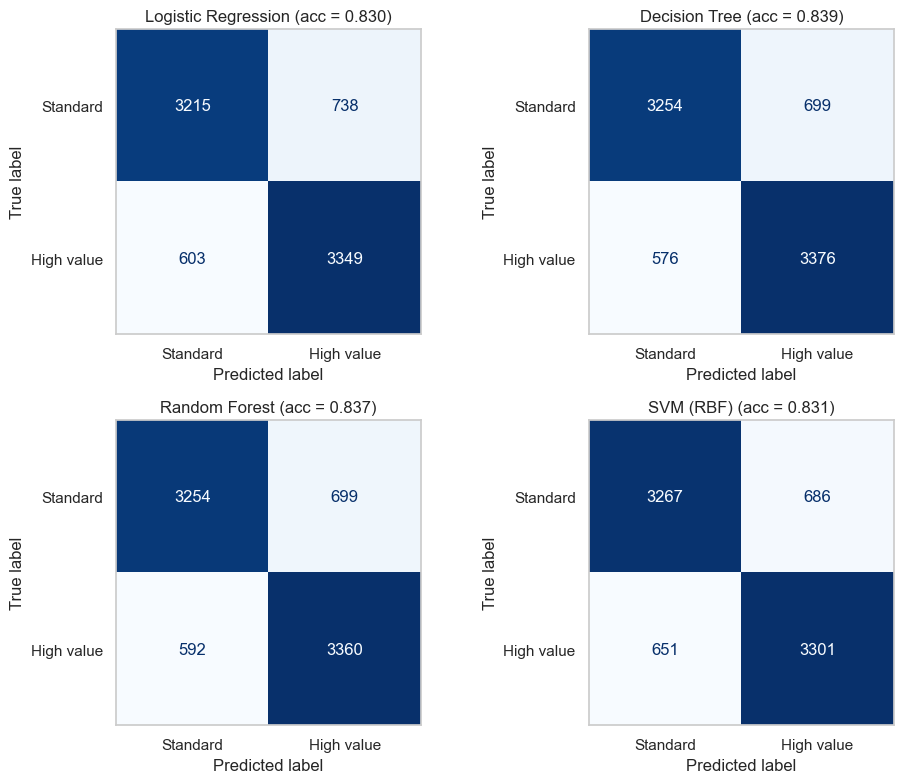

Classification report: Decision Tree
              precision    recall  f1-score   support

    Standard       0.85      0.82      0.84      3953
  High value       0.83      0.85      0.84      3952

    accuracy                           0.84      7905
   macro avg       0.84      0.84      0.84      7905
weighted avg       0.84      0.84      0.84      7905



In [17]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, name in zip(axes.ravel(), models):
    ConfusionMatrixDisplay.from_predictions(y_test, preds[name], ax=ax, colorbar=False,
                                            display_labels=["Standard", "High value"], cmap="Blues")
    ax.set_title(f"{name} (acc = {accuracy_score(y_test, preds[name]):.3f})")
    ax.grid(False)
save_show("09_confusion_matrices")

print(f"Classification report: {best_name}")
print(classification_report(y_test, preds[best_name], target_names=["Standard", "High value"]))

All four models perform similarly, achieving around **83–84% accuracy** in predicting high-value invoices. The Decision Tree performs slightly better at 83.9%, correctly identifying 3,376 high-value invoices while making fewer classification errors than the other models.

Random Forest follows closely, while Logistic Regression and SVM show slightly lower performance. Overall, the results suggest that invoice characteristics can help distinguish high-value purchases from standard ones, although around 16–17% of predictions are still incorrect.

Since the performance differences are small, **Decision Tree appears to be a good choice**, especially because its predictions are easier to interpret and explain.

,importance
log_total_qty,0.73
n_lines,0.20
Hour,0.02
Month,0.01
Country_grp,0.01
DayOfWeek,0.01
IsGuest,0.01


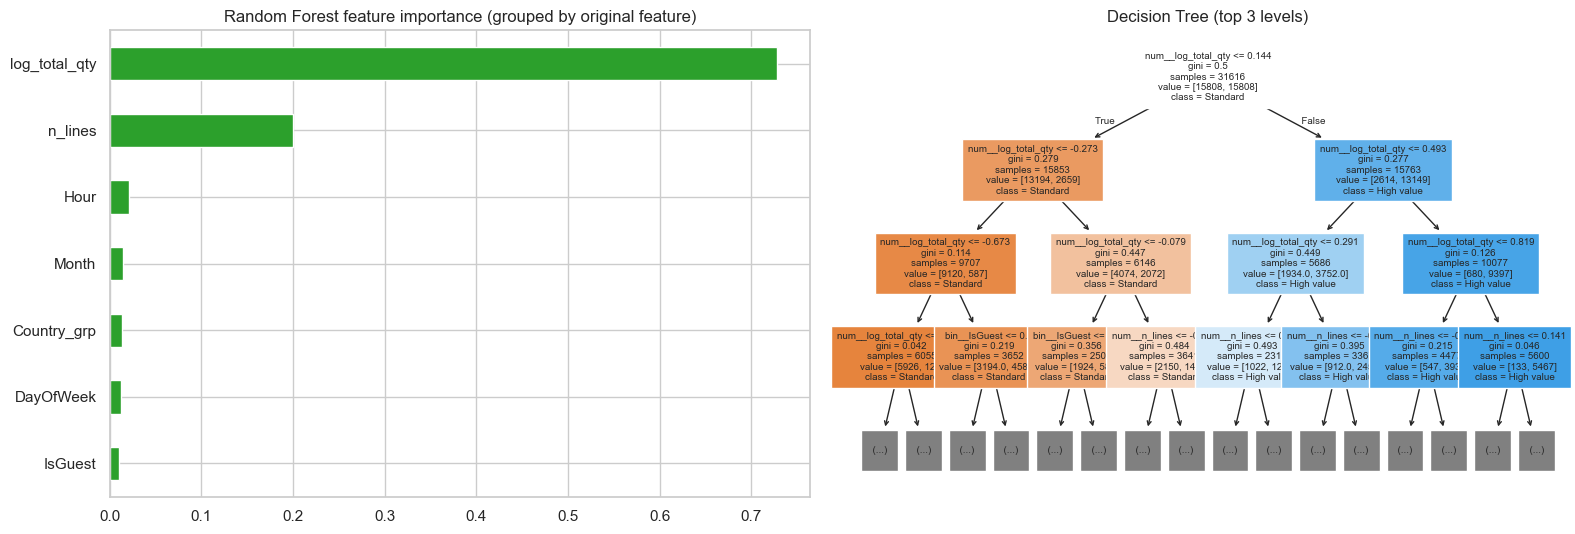

In [18]:
# Which inputs matter? Random Forest importances, summed back to the original feature
rf_pipe = pipes["Random Forest"]
names = rf_pipe.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf_pipe.named_steps["model"].feature_importances_, index=names)

def base_feature(n):
    kind, rest = n.split("__", 1)
    if kind == "cat":
        return next(f for f in cat_feats if rest.startswith(f))
    return rest

rf_importance = imp.groupby(base_feature).sum().sort_values(ascending=False)
display(rf_importance.to_frame("importance"))

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
rf_importance.sort_values().plot.barh(ax=ax[0], color="tab:green")
ax[0].set(title="Random Forest feature importance (grouped by original feature)")
plot_tree(pipes["Decision Tree"].named_steps["model"], max_depth=3, feature_names=list(names),
          class_names=["Standard", "High value"], filled=True, fontsize=7, ax=ax[1])
ax[1].set_title("Decision Tree (top 3 levels)")
save_show("10_feature_importance_tree")

The models show that **total quantity purchased is by far the strongest factor in predicting high-value invoices**, contributing around 73% of the Random Forest's feature importance, followed by the number of product lines at approximately 20%.

The Decision Tree supports this finding, as most of its early decisions are based on total quantity. Meanwhile, factors like purchase time, country, and customer type have very little influence on predictions.

Overall, **how much customers buy matters far more than when or where they shop**. This suggests that encouraging larger purchases and increasing basket size could be valuable business strategies.

### 6.1 Linear Regression: predicting the invoice total

,Linear Regression
R2 (log scale),0.80
MAE (log scale),0.38
RMSE (log scale),0.53
MAE (£),181.65


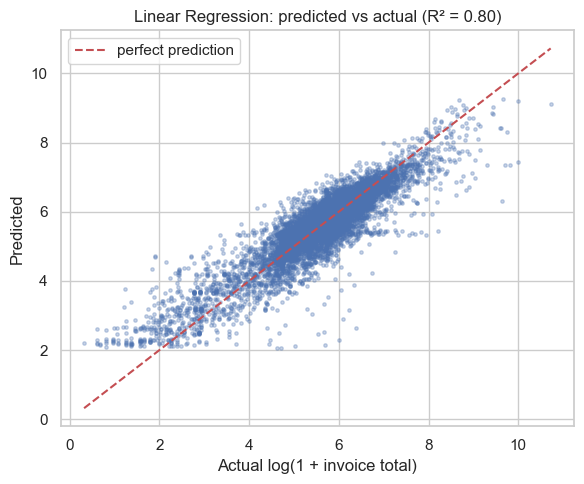

In [19]:
lin = Pipeline([("prep", make_prep()), ("model", LinearRegression())])
lin.fit(X_train, yreg_train)
pred_log = lin.predict(X_test)

lin_metrics = {
    "R2 (log scale)": r2_score(yreg_test, pred_log),
    "MAE (log scale)": mean_absolute_error(yreg_test, pred_log),
    "RMSE (log scale)": mean_squared_error(yreg_test, pred_log) ** 0.5,
    "MAE (£)": mean_absolute_error(np.expm1(yreg_test), np.expm1(pred_log)),
}
lin_df = pd.Series(lin_metrics, name="Linear Regression").to_frame()
display(lin_df)
lin_df.to_csv(OUT / "linear_regression_metrics.csv")

plt.figure(figsize=(6, 5))
plt.scatter(yreg_test, pred_log, s=6, alpha=0.3)
lims = [yreg_test.min(), yreg_test.max()]
plt.plot(lims, lims, "r--", label="perfect prediction")
plt.xlabel("Actual log(1 + invoice total)")
plt.ylabel("Predicted")
plt.title(f"Linear Regression: predicted vs actual (R² = {lin_metrics['R2 (log scale)']:.2f})")
plt.legend()
save_show("11_linear_regression")

The Linear Regression model performs well, achieving an **R² of 0.80**, meaning it explains around 80% of the variation in log-transformed invoice values.

Most predictions are close to the actual values, showing that the model captures the overall spending pattern. However, it tends to overestimate some smaller invoices and underestimate some larger ones.

Overall, the model provides a strong baseline for predicting invoice values, although its accuracy decreases for unusually small or large purchases.

## 7. AI-generated insights and summary

The insights below are generated **automatically from the computed results** (no number is typed by hand), so they update if the data or the cleaning rules change. Each statement is followed by a business-oriented recommendation where the data supports one. The text is saved to `outputs/ai_insights.md`.

> *For the walkthrough video:* this section is the "AI-generated insights" deliverable. You can also paste `outputs/ai_insights.md` and `outputs/model_results.csv` into a generative-AI assistant and ask it to rewrite the findings as an executive summary.

In [20]:
def gbp(x):
    return f"£{x:,.0f}"

insights, recs = [], []

# --- scope
first, last = df_clean["InvoiceDate"].min(), df_clean["InvoiceDate"].max()
total_rev = df_clean["TotalPrice"].sum()
n_orders = df_clean["Invoice"].nunique()
n_cust = df_clean.loc[~df_clean["IsGuest"], "Customer ID"].nunique()
insights.append(f"**Scope.** After cleaning, the data covers {first:%d %b %Y} to {last:%d %b %Y}: {n_orders:,} invoices, "
                f"{n_cust:,} registered customers and {gbp(total_rev)} of revenue. The average order is {gbp(total_rev / n_orders)}, "
                f"but the median order is only {gbp(df_inv['invoice_total'].median())}, so a minority of large (wholesale) orders pulls the average up.")

# --- growth: compare the same complete months across years
pm = df_clean.groupby(["Year", "Month"])["TotalPrice"].sum().unstack(0)
last_year, last_month = last.year, last.month
yoy_text = None
years = sorted(pm.columns)
if len(years) >= 2:
    y0, y1 = years[-2], years[-1]
    common = pm[[y0, y1]].dropna()
    common = common.drop(index=last_month, errors="ignore") if y1 == last_year else common
    if len(common) >= 3:
        g = common[y1].sum() / common[y0].sum() - 1
        yoy_text = (f"**Growth.** For the {len(common)} months present in both {y0} and {y1} (partial final month excluded), "
                    f"revenue changed by {g:+.1%} ({gbp(common[y0].sum())} to {gbp(common[y1].sum())}).")
        insights.append(yoy_text)
        if g > 0.02:
            recs.append("Revenue is growing: keep investing in what works (see products and customers below).")
        elif g < -0.02:
            recs.append("Revenue is shrinking year over year: investigate which months, countries and customer groups declined.")
        else:
            recs.append("Revenue is roughly flat year over year: growth will need new levers such as new markets, products or customer segments.")

# --- seasonality
monthly_full = monthly.iloc[:-1] if len(monthly) > 1 else monthly      # drop the partial last month
peak = monthly_full.loc[monthly_full["Revenue"].idxmax()]
insights.append(f"**Seasonality.** The strongest complete month is {peak['YearMonth']} with {gbp(peak['Revenue'])} in revenue.")
full_year = next((yr for yr in sorted(pm.columns, reverse=True)
                  if pm[yr].notna().sum() == 12 and (yr < last_year or last >= pd.Timestamp(yr, 12, 31))), None)
if full_year:
    share = pm.loc[[9, 10, 11], full_year].sum() / pm[full_year].sum()
    insights.append(f"In {full_year}, September to November delivered {share:.0%} of the year's revenue (the build-up to Christmas).")
    recs.append(f"Plan stock, staffing and marketing around the autumn peak: September to November produced {share:.0%} of {full_year} revenue.")

# --- geography
uk_share = by_country.get("United Kingdom", 0) / by_country.sum()
top_foreign = by_country.drop("United Kingdom", errors="ignore").head(3)
insights.append(f"**Geography.** The UK generates {uk_share:.0%} of revenue. The leading export markets are "
                + ", ".join(f"{c} ({gbp(v)})" for c, v in top_foreign.items()) + ".")
if uk_share > 0.8:
    recs.append(f"Revenue is concentrated in the UK ({uk_share:.0%}). Test targeted promotions in the top export markets to diversify.")

# --- products
top3 = by_prod["Revenue"].nlargest(3)
insights.append("**Products.** The three best sellers by revenue are "
                + "; ".join(f"{p.title()} ({gbp(v)})" for p, v in top3.items())
                + f", together {top3.sum() / total_rev:.1%} of revenue.")

# --- customers
cust_rev = df_clean[~df_clean["IsGuest"]].groupby("Customer ID")["TotalPrice"].sum().sort_values(ascending=False)
top10 = cust_rev.head(max(1, int(len(cust_rev) * 0.1))).sum() / cust_rev.sum()
guest_rev_share = df_clean.loc[df_clean["IsGuest"], "TotalPrice"].sum() / total_rev
guest_order_share = df_inv["IsGuest"].mean()
insights.append(f"**Customers.** The top 10% of registered customers produce {top10:.0%} of registered-customer revenue. "
                f"Guest checkouts account for {guest_order_share:.0%} of invoices and {guest_rev_share:.0%} of revenue.")
if top10 > 0.5:
    recs.append(f"Revenue depends on a small group of customers ({top10:.0%} from the top decile). Build a retention programme (account managers, volume pricing) for them.")
if guest_order_share > 0.15:
    recs.append(f"About {guest_order_share:.0%} of invoices are guest checkouts. Prompting guests to register would improve customer-level tracking and repeat marketing.")

# --- timing
best_day, best_hour = by_dow.idxmax(), by_hour.idxmax()
insights.append(f"**Timing.** {best_day} is the strongest trading day and {best_hour}:00 is the strongest hour. "
                f"The weakest weekday is {by_dow.idxmin()}.")
recs.append(f"Schedule promotions and customer-service cover around {best_day}s and the {best_hour}:00 hour.")

# --- cancellations
cancel_rate_lines = len(df_cancel) / (len(df_cancel) + len(df_clean))
cancel_rate_value = -df_cancel["TotalPrice"].sum() / total_rev
insights.append(f"**Cancellations.** {cancel_rate_lines:.1%} of product lines are cancelled, worth {gbp(-df_cancel['TotalPrice'].sum())} "
                f"({cancel_rate_value:.1%} of net revenue).")
if cancel_rate_value > 0.03:
    recs.append(f"Cancellations are worth {cancel_rate_value:.1%} of revenue. Review the most-cancelled products and customers for quality or listing problems.")

# --- data quality
raw_rows = cleaning_summary.loc[0, "rows_after"]
insights.append(f"**Data quality.** Cleaning removed duplicates (including the December 2010 sheet overlap), cancellations, "
                f"adjustments, non-product codes and fully reversed giant orders. {len(df_clean) / raw_rows:.1%} of the raw rows were kept; "
                f"outliers were capped, not deleted, to preserve legitimate wholesale demand.")

# --- models
best = results_df.iloc[0]
top_feats = rf_importance.head(3)
nice = {"log_total_qty": "total quantity", "n_lines": "number of lines", "IsGuest": "guest checkout", "Country_grp": "country",
        "DayOfWeek": "weekday", "Hour": "hour of day", "Month": "month"}
baseline = max(y_test.mean(), 1 - y_test.mean())
insights.append(f"**Prediction.** Using only order size and context (no price information), the best model for flagging high-value invoices "
                f"(above {gbp(HV_THRESHOLD)}) is {best['model']} with {best['test_accuracy']:.1%} test accuracy "
                f"(F1 {best['f1']:.2f}, ROC-AUC {best['roc_auc']:.2f}) against a {baseline:.0%} majority-class baseline. "
                f"The most informative inputs are {', '.join(nice.get(f, f) for f in top_feats.index)}. "
                f"Linear Regression explains {lin_metrics['R2 (log scale)']:.0%} of the variance in log invoice value.")
recs.append("Use the high-value probability from the model (exported for the dashboard) to prioritise sales follow-up on large pending orders and to forecast demand.")

report = "# AI-generated insights\n\n## Key findings\n\n" + "\n\n".join(f"- {t}" for t in insights) \
         + "\n\n## Recommendations\n\n" + "\n".join(f"{i}. {t}" for i, t in enumerate(recs, 1)) + "\n"
(OUT / "ai_insights.md").write_text(report, encoding="utf-8")

from IPython.display import Markdown
display(Markdown(report))

# AI-generated insights

## Key findings

- **Scope.** After cleaning, the data covers 01 Dec 2009 to 09 Dec 2011: 39,521 invoices, 5,853 registered customers and £19,413,406 of revenue. The average order is £491, but the median order is only £301, so a minority of large (wholesale) orders pulls the average up.

- **Growth.** For the 11 months present in both 2010 and 2011 (partial final month excluded), revenue changed by +2.1% (£8,605,482 to £8,786,758).

- **Seasonality.** The strongest complete month is 2011-11 with £1,453,266 in revenue.

- In 2010, September to November delivered 36% of the year's revenue (the build-up to Christmas).

- **Geography.** The UK generates 85% of revenue. The leading export markets are EIRE (£633,269), Netherlands (£549,773), Germany (£383,289).

- **Products.** The three best sellers by revenue are Regency Cakestand 3 Tier (£330,590); White Hanging Heart T-Light Holder (£260,990); Party Bunting (£148,318), together 3.8% of revenue.

- **Customers.** The top 10% of registered customers produce 63% of registered-customer revenue. Guest checkouts account for 7% of invoices and 13% of revenue.

- **Timing.** Thursday is the strongest trading day and 12:00 is the strongest hour. The weakest weekday is Saturday.

- **Cancellations.** 1.8% of product lines are cancelled, worth £471,132 (2.4% of net revenue).

- **Data quality.** Cleaning removed duplicates (including the December 2010 sheet overlap), cancellations, adjustments, non-product codes and fully reversed giant orders. 94.0% of the raw rows were kept; outliers were capped, not deleted, to preserve legitimate wholesale demand.

- **Prediction.** Using only order size and context (no price information), the best model for flagging high-value invoices (above £301) is Decision Tree with 83.9% test accuracy (F1 0.84, ROC-AUC 0.92) against a 50% majority-class baseline. The most informative inputs are total quantity, number of lines, hour of day. Linear Regression explains 80% of the variance in log invoice value.

## Recommendations

1. Revenue is growing: keep investing in what works (see products and customers below).
2. Plan stock, staffing and marketing around the autumn peak: September to November produced 36% of 2010 revenue.
3. Revenue is concentrated in the UK (85%). Test targeted promotions in the top export markets to diversify.
4. Revenue depends on a small group of customers (63% from the top decile). Build a retention programme (account managers, volume pricing) for them.
5. Schedule promotions and customer-service cover around Thursdays and the 12:00 hour.
6. Use the high-value probability from the model (exported for the dashboard) to prioritise sales follow-up on large pending orders and to forecast demand.


## 8. Exports for the interactive dashboard (Power BI / Tableau)

Everything is written to `outputs/powerbi/`. Suggested dashboard design:

* **KPI cards:** total revenue, orders, average order value, registered customers, cancellation rate (from `kpis.csv` or DAX measures on the fact tables).
* **Slicers / filters:** `Year`, `Month`, `Country`, `source_sheet` (2009-2010 vs 2010-2011), `IsGuest`.
* **Drill-down:** Year → Month → Day of week for revenue, and Country → Customer for geography.
* **Predictive page:** `fact_invoices.csv` contains `HighValue_Probability` and `HighValue_Predicted` per invoice, plus the actual `HighValue` label and the `split` (train/test). Filter to `test` to show honest performance.

Useful DAX measures: `Revenue = SUM(fact_sales_lines[TotalPrice])`, `Orders = DISTINCTCOUNT(fact_sales_lines[Invoice])`, `AOV = DIVIDE([Revenue], [Orders])`.

In [21]:
# Random Forest probabilities for every invoice (it supports predict_proba)
proba = pipes["Random Forest"].predict_proba(df_inv[features])[:, 1]
df_inv["split"] = np.where(df_inv.index.isin(X_test.index), "test", "train")
df_inv["HighValue_Probability"] = proba
df_inv["HighValue_Predicted"] = (proba >= 0.5).astype(int)
df_inv["Predicted_Invoice_Total_Linear"] = np.expm1(lin.predict(df_inv[features]))

kpis = pd.DataFrame({
    "kpi": ["Total revenue (£)", "Invoices", "Average order value (£)", "Median order value (£)", "Registered customers",
            "Guest share of invoices", "Cancellation rate (lines)", "Cancellation value (% of revenue)",
            "High-value threshold (£)", f"Best model: {best['model']} (test accuracy)"],
    "value": [total_rev, n_orders, total_rev / n_orders, df_inv["invoice_total"].median(), n_cust,
              guest_order_share, cancel_rate_lines, cancel_rate_value, HV_THRESHOLD, best["test_accuracy"]],
})

df_clean.to_csv(PBI / "fact_sales_lines.csv", index=False)
df_cancel.to_csv(PBI / "fact_cancellations.csv", index=False)
df_inv.to_csv(PBI / "fact_invoices.csv", index=False)
monthly.to_csv(PBI / "summary_monthly.csv", index=False)
kpis.to_csv(PBI / "kpis.csv", index=False)
display(kpis)

print("\nFiles written:")
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print(f"  {str(p):55s} {p.stat().st_size / 1e6:8.2f} MB")

,kpi,value
0,Total revenue (£),"19,413,405.64"
1,Invoices,"39,521.00"
2,Average order value (£),491.22
3,Median order value (£),301.34
4,Registered customers,"5,853.00"
5,Guest share of invoices,0.07
6,Cancellation rate (lines),0.02
7,Cancellation value (% of revenue),0.02
8,High-value threshold (£),301.34
9,Best model: Decision Tree (test accuracy),0.84



Files written:
  outputs\ai_insights.md                                      0.00 MB
  outputs\cleaning_log.csv                                    0.00 MB
  outputs\figures\01_outlier_capping.png                      0.04 MB
  outputs\figures\02_monthly_revenue_aov.png                  0.13 MB
  outputs\figures\03_country_revenue.png                      0.06 MB
  outputs\figures\04_top_products.png                         0.11 MB
  outputs\figures\05_distributions.png                        0.07 MB
  outputs\figures\06_scatter_relationships.png                0.23 MB
  outputs\figures\07_correlation_heatmap.png                  0.10 MB
  outputs\figures\08_timing.png                               0.04 MB
  outputs\figures\09_confusion_matrices.png                   0.08 MB
  outputs\figures\10_feature_importance_tree.png              0.22 MB
  outputs\figures\11_linear_regression.png                    0.13 MB
  outputs\linear_regression_metrics.csv                       0.00 MB
  ou

## 9. How generative AI was used in this project

| Phase | AI assistance |
|---|---|
| Loading | Recommended concatenating the two sheets, tagging rows with `source_sheet`, and validating columns, row counts and date ranges |
| Duplicates | Explained the `keep=False` vs `keep="first"` difference and how to split the sheet overlap from repeated rows |
| Missing values | Suggested diagnosing missing descriptions before dropping them and flagging guest customers instead of deleting 23% of rows |
| Invalid rows / anomalies | Proposed the rule set for cancellations, non-product codes and non-sale invoice numbers, and the reversal check for giant orders |
| Outliers | Suggested the flag-inspect-cap approach, with Isolation Forest as an unsupervised second opinion |
| Modeling | Helped define a balanced target, avoid price-based leakage, and choose evaluation metrics |
| Insights | Section 7 generates natural-language findings and recommendations directly from the computed results |

All AI suggestions were checked against the data (row counts reconcile at every step, see `outputs/cleaning_log.csv`).

## 10. Deliverables checklist

| Deliverable | Where |
|---|---|
| Cleaned and prepared dataset | `outputs/online_retail_clean_final.csv`, `outputs/cleaning_log.csv` |
| Exploratory analysis and visualizations | Section 5 and `outputs/figures/` |
| Predictive models with evaluation metrics | Section 6 and `outputs/model_results.csv` |
| AI-generated insights and summary | Section 7 and `outputs/ai_insights.md` |
| Interactive dashboard inputs | `outputs/powerbi/` (build the dashboard in Power BI or Tableau) |
| Face-cam walkthrough | Record separately: objectives, cleaning log, EDA, models, dashboard demo, AI insights |